<a href="https://colab.research.google.com/github/Finoria-co/fridge-chef-ai/blob/main/roboflow_fridge_merge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ดึงภาพตู้เย็นจาก Roboflow แล้วรวมกับ foodseg_yolo


## ติดตั้งและเชื่อม Drive


In [1]:
!pip install -q roboflow ultralytics
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## ตั้งค่า

In [14]:
WORKSPACE = "tk-matima-unqyz"
PROJECT   = "foodtypes-individual-in-fridge"
VERSION   = 1

DRIVE_DIR = "/content/drive/MyDrive/fridge_project"
BASE_ZIP  = "/content/drive/MyDrive/foodseg/foodseg_yolo.zip"
OUT_ZIP   = f"{DRIVE_DIR}/foodseg_fridge_yolo.zip"
RF_DIR    = "/content/fridge_rf"
BASE_DIR  = "/content/foodseg_yolo"
REPEAT    = 1

## ดาวน์โหลดจาก Roboflow

In [4]:
from roboflow import Roboflow
try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    from getpass import getpass
    API_KEY = getpass("Roboflow API key: ")

rf = Roboflow(api_key=API_KEY)
version = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION)
try:
    version.download("yolov11", location=RF_DIR, overwrite=True)
except Exception as e:
    print("yolov11 ไม่ได้ ลอง yolov8 แทน:", e)
    version.download("yolov8", location=RF_DIR, overwrite=True)
!ls {RF_DIR}

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/fridge_rf in yolov11:: 100%|██████████| 6498/6498 [00:01<00:00, 4172.08it/s]


data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


## ชื่อคลาส จำนวนภาพ และชนิด label

In [5]:
import glob, os, yaml, collections

def load_names(path):
    n = yaml.safe_load(open(path))["names"]
    return list(n.values()) if isinstance(n, dict) else list(n)

def label_kind(split_dir):
    kind = collections.Counter()
    for f in glob.glob(f"{split_dir}/labels/*.txt"):
        for line in open(f):
            n = len(line.split())
            if n:
                kind["box" if n == 5 else "polygon"] += 1
    return kind

SPLITS = [s for s in ("train", "valid", "test") if os.path.isdir(f"{RF_DIR}/{s}/images")]
rf_names = load_names(f"{RF_DIR}/data.yaml")
print(f"คลาสใน Roboflow ({len(rf_names)}):", rf_names)
for s in SPLITS:
    n_img = len(glob.glob(f"{RF_DIR}/{s}/images/*"))
    print(f"{s}: {n_img} ภาพ, label: {dict(label_kind(f'{RF_DIR}/{s}'))}")

คลาสใน Roboflow (138): ['-', 'Apple', 'Artichoke', 'Asparagus', 'Avocado', 'Banana', 'Beans', 'Beetroot', 'Blackberries', 'Blueberries', 'Book', 'Broccoli', 'Brussel Sprouts', 'Butter', 'Cabbage', 'Cantaloupe', 'Carrots', 'Cauliflower', 'Cerealbox', 'Cheese', 'Clementine', 'Coffee', 'Corn', 'Cucumber', 'Detergent', 'Drinks', 'Egg', 'Eggplant', 'Eggs', 'Fish', 'Galia', 'Grapes', 'Honeydew', 'Juice', 'Lemon', 'Lettuce', 'Meat', 'Milk', 'Mushroom', 'Mushrooms', 'Nectarine', 'Onion', 'Orange', 'Oranges', 'Peas', 'Pineapple', 'Plum', 'Pomegranate', 'Potato', 'Raspberries', 'Salad', 'Sauce', 'Shallot', 'Spinach', 'Squash', 'Strawberries', 'Strawberry', 'Sweetcorn', 'Tofu', 'Tomato', 'Tomatoes', 'Watermelon', 'Yogurt', 'Zucchini', 'apple', 'apples', 'asparagus', 'aubergine', 'bacon', 'banana', 'bananas', 'bazlama', 'beef', 'blueberries', 'bread', 'broccoli', 'butter', 'carrot', 'carrots', 'cheese', 'chicken', 'chicken_breast', 'chocolate', 'chocolate chips', 'corn', 'courgettes', 'cream', 'cr

## แปลงกรอบเป็น polygon ด้วย SAM


In [6]:
import shutil
from ultralytics.data.converter import yolo_bbox2segment

for s in SPLITS:
    d = f"{RF_DIR}/{s}"
    if label_kind(d)["box"] == 0:
        print(f"{s}: เป็น polygon แล้ว ข้าม")
        continue
    yolo_bbox2segment(im_dir=f"{d}/images", save_dir=f"{d}/labels_seg", sam_model="sam_b.pt")
    if not os.path.isdir(f"{d}/labels_box"):
        shutil.move(f"{d}/labels", f"{d}/labels_box")
    if os.path.isdir(f"{d}/labels"):
        shutil.rmtree(f"{d}/labels")
    shutil.move(f"{d}/labels_seg", f"{d}/labels")
    print(f"{s}: แปลงแล้ว ->", dict(label_kind(d)))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1906.8±847.8 MB/s, size: 68.0 KB)
Scanning /content/fridge_rf/train/labels... 2276 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2276/2276 1.9Kit/s 1.2s
New cache created: /content/fridge_rf/train/labels.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
Detection labels detected, generating segment labels by SAM model!
Generating segment labels: 100% ━━━━━━━━━━━━ 2276/2276 1.8it/s 21:01
Generated segment labels saved in /content/fridge_rf/train/labels_seg
train: แปลงแล้ว -> {'polygo

##เส้นขอบต้องทับวัตถุพอดี

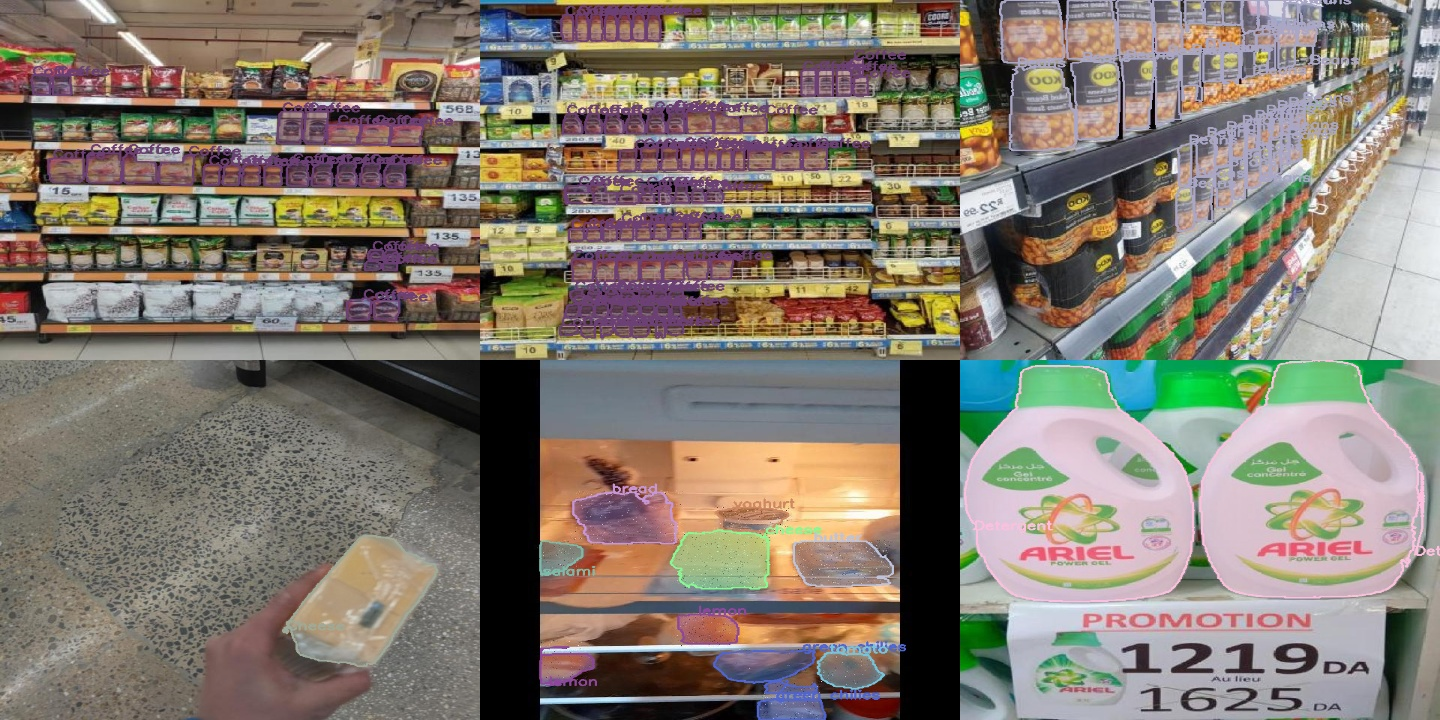

In [7]:
import cv2, numpy as np, random
from IPython.display import Image as Show, display

def draw_grid(img_dir, names, out, n=6, seed=0):
    imgs = sorted(glob.glob(f"{img_dir}/*"))
    random.seed(seed); tiles = []
    for p in random.sample(imgs, min(n, len(imgs))):
        im = cv2.imread(p); h, w = im.shape[:2]
        lbl = os.path.join(os.path.dirname(os.path.dirname(p)), "labels",
                           os.path.splitext(os.path.basename(p))[0] + ".txt")
        lines = open(lbl).read().splitlines() if os.path.exists(lbl) else []
        for line in lines:
            v = line.split()
            if len(v) < 7: continue
            c = int(v[0])
            pts = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).astype(np.int32)
            col = [int(x) for x in np.random.RandomState(c).randint(60, 255, 3)]
            ov = im.copy(); cv2.fillPoly(ov, [pts], col); im = cv2.addWeighted(ov, 0.4, im, 0.6, 0)
            cv2.polylines(im, [pts], True, col, 2)
            cv2.putText(im, str(names[c]), tuple(pts[0]), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
        tiles.append(cv2.resize(im, (480, 360)))
    while len(tiles) % 3: tiles.append(np.zeros_like(tiles[0]))
    grid = np.vstack([np.hstack(tiles[i:i+3]) for i in range(0, len(tiles), 3)])
    cv2.imwrite(out, grid); display(Show(out))

draw_grid(f"{RF_DIR}/train/images", rf_names, "/content/check_rf.jpg")

## talicized text แตก foodseg_yolo.zip จาก Drive

In [15]:
!rm -rf {BASE_DIR}
!unzip -q {BASE_ZIP} -d /content
base_names = load_names(f"{BASE_DIR}/data.yaml")
print(f"ชุดเดิมมี {len(base_names)} คลาส")
for i, n in enumerate(base_names):
    print(f"{i:>2}: {n}", end="   " if (i + 1) % 6 else "\n")

ชุดเดิมมี 53 คลาส
 0: cheese butter            1: milk                     2: egg                      3: apple                   
 4: avocado                  5: banana                   6: strawberry               7: mango                   
 8: lemon                    9: grape                   10: orange                  11: steak                   
12: pork                    13: chicken duck            14: sausage                 15: crab                    
16: fish                    17: shellfish               18: shrimp                  19: bread                   
20: corn                    21: tofu                    22: eggplant                23: potato                  
24: garlic                  25: cauliflower             26: tomato                  27: spring onion            
28: rape                    29: ginger                  30: okra                    31: lettuce                 
32: pumpkin                 33: cucumber                34: white radish      

## จับคู่ชื่อคลาส

In [16]:
RENAME = {
    "apples": "apple",
    "bananas": "banana",
    "Carrots": "carrot", "carrots": "carrot",
    "Cheese": "cheese butter", "cheese": "cheese butter",
    "Butter": "cheese butter", "butter": "cheese butter",
    "beef": "steak",
    "chicken": "chicken duck", "chicken_breast": "chicken duck",
    "Eggs": "egg", "eggs": "egg",
    "aubergine": "eggplant",
    "Grapes": "grape", "red grapes": "grape",
    "lemons": "lemon",
    "Oranges": "orange",
    "Potatoes": "potato", "potatoes": "potato",
    "Sweetcorn": "corn",
    "Tomatoes": "tomato", "tomatoes": "tomato",
    "Strawberries": "strawberry", "strawberries": "strawberry",
    "Peppers": "pepper", "peppers": "pepper",
    "green bell pepper": "pepper", "red bell pepper": "pepper",
    "yellow bell pepper": "pepper", "green chilies": "pepper",
    "green_beans": "green beans",
    "red onion": "onion",
    "bazlama": "bread",
}
DROP = [
    "-", "Book", "Cerealbox", "Detergent", "Drinks", "Coffee",
    "mineral water", "Juice", "juice",
]

lower = [n.lower().strip() for n in base_names]
plan, new_classes = {}, []
for i, n in enumerate(rf_names):
    if n in DROP:
        plan[i] = None
        print(f"  {n!r:<25} -> ตัดทิ้ง")
        continue
    target = RENAME.get(n, n).strip()
    if target.lower() in lower:
        plan[i] = lower.index(target.lower())
        print(f"  {n!r:<25} -> {plan[i]}: {base_names[plan[i]]}")
    else:
        new_classes.append(target)
        plan[i] = len(base_names) + len(new_classes) - 1
        print(f"  {n!r:<25} -> คลาสใหม่ {plan[i]}: {target}")

print(f"\nคลาสใหม่ {len(new_classes)} ตัว รวมทั้งหมดจะเป็น {len(base_names) + len(new_classes)} คลาส")

  '-'                       -> ตัดทิ้ง
  'Apple'                   -> 3: apple
  'Artichoke'               -> คลาสใหม่ 53: Artichoke
  'Asparagus'               -> 36: asparagus
  'Avocado'                 -> 4: avocado
  'Banana'                  -> 5: banana
  'Beans'                   -> คลาสใหม่ 54: Beans
  'Beetroot'                -> คลาสใหม่ 55: Beetroot
  'Blackberries'            -> คลาสใหม่ 56: Blackberries
  'Blueberries'             -> คลาสใหม่ 57: Blueberries
  'Book'                    -> ตัดทิ้ง
  'Broccoli'                -> 38: broccoli
  'Brussel Sprouts'         -> คลาสใหม่ 58: Brussel Sprouts
  'Butter'                  -> 0: cheese butter
  'Cabbage'                 -> 42: cabbage
  'Cantaloupe'              -> คลาสใหม่ 59: Cantaloupe
  'Carrots'                 -> 35: carrot
  'Cauliflower'             -> 25: cauliflower
  'Cerealbox'               -> ตัดทิ้ง
  'Cheese'                  -> 0: cheese butter
  'Clementine'              -> คลาสใหม่ 60: Clementine
  '

## รวมชุดข้อมูล

In [17]:
all_names = base_names + new_classes
count = collections.Counter()
for rf_split, split, rep in (("train", "train", REPEAT), ("valid", "val", 1), ("test", "val", 1)):
    if rf_split not in SPLITS: continue
    for p in glob.glob(f"{RF_DIR}/{rf_split}/images/*"):
        stem, ext = os.path.splitext(os.path.basename(p))
        lbl = f"{RF_DIR}/{rf_split}/labels/{stem}.txt"
        out = []
        for line in (open(lbl).read().splitlines() if os.path.exists(lbl) else []):
            v = line.split()
            if len(v) < 7: continue                 # ข้ามบรรทัดที่ไม่ใช่ polygon
            new_c = plan[int(v[0])]
            if new_c is None: continue              # คลาสที่อยู่ใน DROP
            out.append(" ".join([str(new_c)] + v[1:]))
        for r in range(rep):
            name = f"fridge_{rf_split}_{stem}_r{r}"
            shutil.copy(p, f"{BASE_DIR}/images/{split}/{name}{ext}")
            with open(f"{BASE_DIR}/labels/{split}/{name}.txt", "w") as f:
                f.write("\n".join(out))
            count[split] += 1

cfg = yaml.safe_load(open(f"{BASE_DIR}/data.yaml"))
cfg["path"] = BASE_DIR
cfg["nc"] = len(all_names)
cfg["names"] = {i: n for i, n in enumerate(all_names)}
yaml.safe_dump(cfg, open(f"{BASE_DIR}/data.yaml", "w"), allow_unicode=True, sort_keys=False)
print("เพิ่มภาพ:", dict(count), "| คลาสรวม", len(all_names))

เพิ่มภาพ: {'train': 2276, 'val': 967} | คลาสรวม 108


### ตรวจชุดที่รวมแล้ว

In [18]:
nc = len(all_names); per_class = collections.Counter()
for split in ("train", "val"):
    imgs = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{BASE_DIR}/images/{split}/*")}
    lbls = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{BASE_DIR}/labels/{split}/*.txt")}
    bad = collections.Counter()
    for k in lbls:
        for line in open(f"{BASE_DIR}/labels/{split}/{k}.txt").read().splitlines():
            v = line.split()
            if not v: continue
            c = int(v[0]); xy = [float(x) for x in v[1:]]
            bad["คลาสเกิน nc"] += not (0 <= c < nc)
            bad["จุดไม่ครบคู่/น้อยกว่า 3"] += (len(xy) % 2 == 1 or len(xy) < 6)
            bad["พิกัดนอก 0-1"] += any(x < 0 or x > 1 for x in xy)
            if split == "train": per_class[c] += 1
    fridge = sum(k.startswith("fridge_") for k in imgs)
    print(f"[{split}] ภาพ {len(imgs)} | label {len(lbls)} | ไม่มีคู่ {len(imgs ^ lbls)} | ภาพตู้เย็น {fridge} | ปัญหา {dict(bad)}")

print("\nคลาสที่มีวัตถุใน train น้อยกว่า 30 ชิ้น (โมเดลจะเรียนได้ไม่ดี):")
for i, n in enumerate(all_names):
    if per_class[i] < 30: print(f"  {i}: {n} = {per_class[i]}")

[train] ภาพ 7259 | label 7259 | ไม่มีคู่ 0 | ภาพตู้เย็น 2276 | ปัญหา {'คลาสเกิน nc': 0, 'จุดไม่ครบคู่/น้อยกว่า 3': 0, 'พิกัดนอก 0-1': 0}
[val] ภาพ 3102 | label 3102 | ไม่มีคู่ 0 | ภาพตู้เย็น 967 | ปัญหา {'คลาสเกิน nc': 0, 'จุดไม่ครบคู่/น้อยกว่า 3': 0, 'พิกัดนอก 0-1': 0}

คลาสที่มีวัตถุใน train น้อยกว่า 30 ชิ้น (โมเดลจะเรียนได้ไม่ดี):
  15: crab = 19
  37: bamboo shoots = 8
  48: king oyster mushroom = 12
  50: enoki mushroom = 9
  51: oyster mushroom = 11
  53: Artichoke = 3
  55: Beetroot = 5
  56: Blackberries = 14
  57: Blueberries = 8
  58: Brussel Sprouts = 20
  60: Clementine = 15
  67: Peas = 19
  68: Pineapple = 1
  69: Plum = 21
  70: Pomegranate = 0
  71: Raspberries = 21
  74: Shallot = 0
  75: Spinach = 4
  80: bacon = 24
  82: chocolate = 9
  83: chocolate chips = 1
  84: courgettes = 5
  85: cream = 17
  87: dates = 1
  88: flour = 21
  89: goat_cheese = 12
  90: ground_beef = 12
  92: heavy_cream = 13
  95: mushroom = 22
  96: mushrooms = 24
  98: olives = 12
  99: parsl

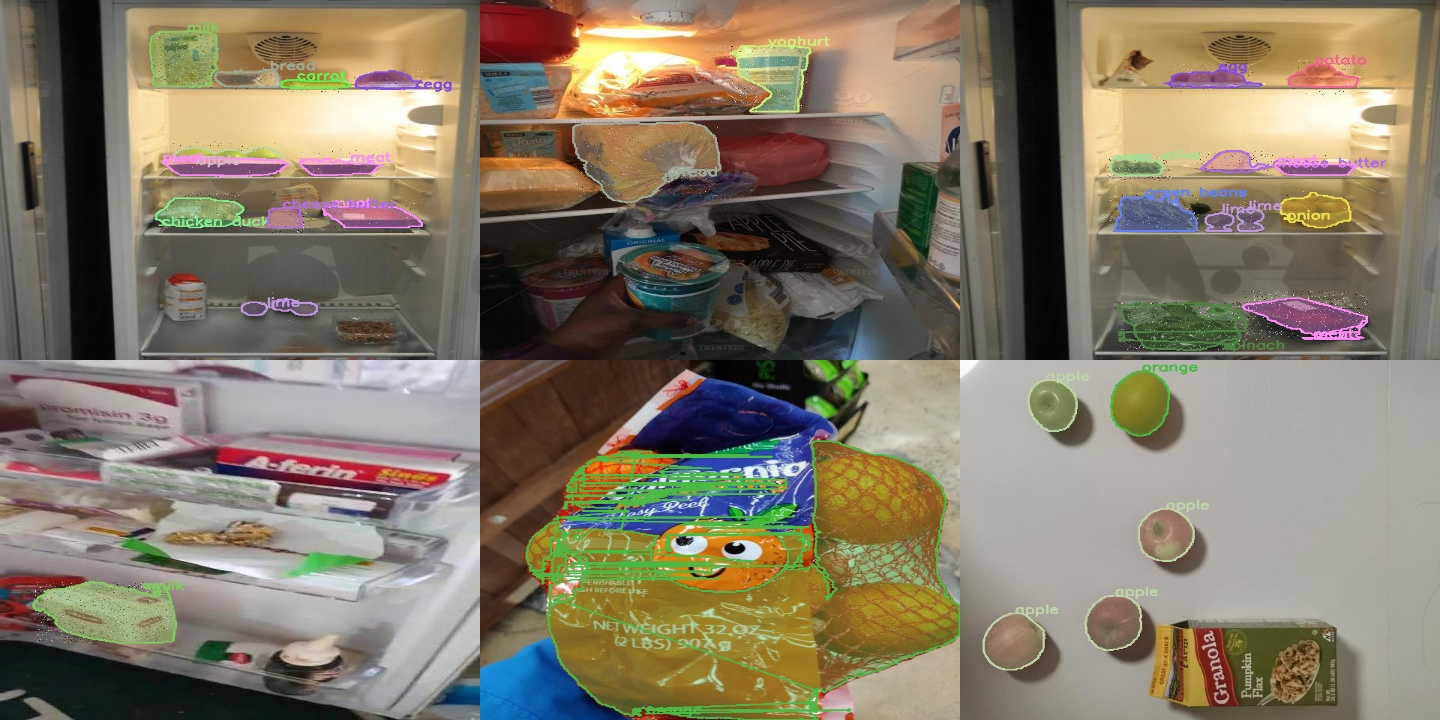

In [19]:
fr = [p for p in glob.glob(f"{BASE_DIR}/images/train/fridge_*")]
shutil.rmtree("/content/_peek", ignore_errors=True)
tmp = "/content/_peek/images"; os.makedirs(tmp, exist_ok=True)
os.makedirs("/content/_peek/labels", exist_ok=True)
for p in random.sample(fr, min(6, len(fr))):
    stem = os.path.splitext(os.path.basename(p))[0]
    shutil.copy(p, tmp); shutil.copy(f"{BASE_DIR}/labels/train/{stem}.txt", "/content/_peek/labels")
draw_grid(tmp, all_names, "/content/check_merged.jpg", seed=1)

In [24]:
import glob, os, yaml, collections

if not os.path.isdir(BASE_DIR):
    !unzip -q "{OUT_ZIP}" -d /content

MERGE = {
    "mushrooms": "mushroom", "enoki mushroom": "mushroom", "oyster mushroom": "mushroom",
    "king oyster mushroom": "mushroom", "white button mushroom": "mushroom", "shiitake": "mushroom",
    "olives": "olive",
    "courgettes": "zucchini",
    "chocolate chips": "chocolate",
    "heavy cream": "cream",
    "ground beef": "steak",
    "clementine": "orange",
    "nectarine": "peach",
    "galia": "melon", "honeydew": "melon", "cantaloupe": "melon",
    "yoghurt": "yogurt",
}
MIN_TRAIN = 20

cfg = yaml.safe_load(open(f"{BASE_DIR}/data.yaml"))
old = cfg["names"]; old = [old[i] for i in sorted(old)] if isinstance(old, dict) else list(old)

def norm(n):
    n = n.strip().lower().replace("_", " ")
    return MERGE.get(n, n)

merged = [norm(n) for n in old]
order = list(dict.fromkeys(merged))

files = {s: glob.glob(f"{BASE_DIR}/labels/{s}/*.txt") for s in ("train", "val")}
count = collections.Counter()
for f in files["train"]:
    for line in open(f):
        v = line.split()
        if v: count[merged[int(v[0])]] += 1

keep = [n for n in order if count[n] >= MIN_TRAIN]
dropped = [(n, count[n]) for n in order if count[n] < MIN_TRAIN]
new_id = {n: i for i, n in enumerate(keep)}
old2new = {i: new_id.get(merged[i]) for i in range(len(old))}

removed = collections.Counter()
for s, fs in files.items():
    for f in fs:
        out = []
        for line in open(f).read().splitlines():
            v = line.split()
            if not v: continue
            c = old2new[int(v[0])]
            if c is None:
                removed[s] += 1; continue
            out.append(" ".join([str(c)] + v[1:]))
        with open(f, "w") as fh:
            fh.write("\n".join(out))

cfg["nc"] = len(keep)
cfg["names"] = {i: n for i, n in enumerate(keep)}
yaml.safe_dump(cfg, open(f"{BASE_DIR}/data.yaml", "w"), allow_unicode=True, sort_keys=False)
for f in glob.glob(f"{BASE_DIR}/labels/*.cache"):
    os.remove(f)

print(f"คลาส: {len(old)} -> {len(keep)}")
print(f"วัตถุที่ถูกตัด: train {removed['train']}, val {removed['val']}")
print(f"คลาสที่ตัดทิ้ง (< {MIN_TRAIN} ชิ้นใน train):", ", ".join(f"{n}({c})" for n, c in dropped))
print("\nคลาสที่เหลือ:")
for i, n in enumerate(keep):
    print(f"{i:>3}: {n:<22}{count[n]:>6}", end="\n" if (i + 1) % 3 == 0 else "   ")
print()

คลาส: 71 -> 71
วัตถุที่ถูกตัด: train 0, val 0
คลาสที่ตัดทิ้ง (< 20 ชิ้นใน train): 

คลาสที่เหลือ:
  0: cheese butter           1008     1: milk                     512     2: egg                     3037
  3: apple                    560     4: avocado                  231     5: banana                   338
  6: strawberry               858     7: mango                     78     8: lemon                    920
  9: grape                    204    10: orange                   470    11: steak                    964
 12: pork                     610    13: chicken duck            1177    14: sausage                  380
 15: fish                     325    16: shellfish                 73    17: shrimp                   219
 18: bread                   1708    19: corn                     436    20: tofu                     139
 21: eggplant                  55    22: potato                  1061    23: garlic                   140
 24: cauliflower              308    25: tomato       

## บีบอัดขึ้น Drive

In [23]:
%cd /content
!rm -f /content/foodseg_fridge_yolo.zip
!zip -qr /content/foodseg_fridge_yolo.zip foodseg_yolo
!cp /content/foodseg_fridge_yolo.zip {OUT_ZIP}
!ls -lh {DRIVE_DIR}

/content
total 2.8G
-rw------- 1 root root 4.9K Nov 10 06:50 convert_foodseg103.py
-rw------- 1 root root 1.5G Nov 10 09:49 foodseg_fridge_yolo.zip
-rw------- 1 root root 1.3G Nov 10 09:30 foodseg_yolo.zip
drwx------ 4 root root 4.0K Nov 10 06:50 test_yolo
